In [1]:
# Cell 1 — Imports & setup
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src.transformers import load_all_months, load_june_logs
from config import (
    FIGURES_DIR,
    DATA_PROC_DIR,
    ALLOWED_AGENTS,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROC_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Cell 2 — Load semua bulan untuk analisis tren
print("Membaca semua bulan dari arsip...")
df_all = load_all_months()
print(f"Total baris semua bulan : {len(df_all):,}")
print(f"Bulan tersedia          : {sorted(df_all['month'].unique())}")

Membaca semua bulan dari arsip...
Total baris semua bulan : 912,979
Bulan tersedia          : ['Aug', 'Dec', 'Jul', 'Jun', 'May', 'Nov', 'Oct', 'Sep']


In [4]:
# Cell 3 — Jumlah alert per bulan

monthly = (
    df_all.groupby("month")
    .size()
    .reset_index(name="alert_count")
)

month_order = ["May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly["month"] = pd.Categorical(
    monthly["month"], categories=month_order, ordered=True
)
monthly = monthly.sort_values("month")
print(monthly.to_string(index=False))

month  alert_count
  May       118698
  Jun       429269
  Jul        55394
  Aug        41506
  Sep       119534
  Oct        45905
  Nov        52521
  Dec        50152


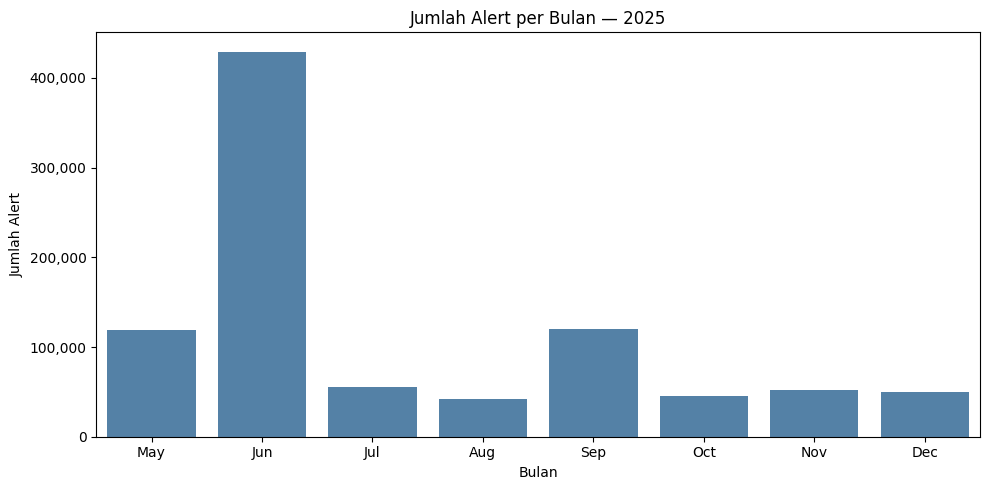

In [5]:
# Cell 4 — Visualisasi tren per bulan
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=monthly, x="month", y="alert_count", ax=ax, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Jumlah Alert per Bulan — 2025")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Alert")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tren_alert_per_bulan.png", dpi=150)
plt.show()

In [6]:
# Cell 5 — Justifikasi pilih Juni
juni_count = monthly.loc[monthly["month"] == "Jun", "alert_count"].values[0]
max_count  = monthly["alert_count"].max()
max_month  = monthly.loc[monthly["alert_count"] == max_count, "month"].values[0]

print(f"Jumlah alert Juni            : {juni_count:,}")
print(f"Bulan dengan alert terbanyak : {max_month} ({max_count:,})")
print()
if juni_count == max_count:
    print("✓ Juni adalah bulan dengan alert terbanyak → dipilih sebagai dataset penelitian.")
else:
    print(f"! Bulan terbanyak adalah {max_month}, bukan Juni.")
    print("  Sesuaikan TARGET_MONTH di config.py jika ingin menggunakan bulan tersebut.")

Jumlah alert Juni            : 429,269
Bulan dengan alert terbanyak : Jun (429,269)

✓ Juni adalah bulan dengan alert terbanyak → dipilih sebagai dataset penelitian.


In [7]:
# Cell 6 — Load Data Mentah Juni & Audit Kualitas Data
print("Membaca log mentah Juni...")
df_raw = load_june_logs()
print(f"Total baris raw data Juni    : {len(df_raw):,}")

# Filter agent yang relevan sesuai config
df_raw = df_raw[df_raw["agent_name"].isin(ALLOWED_AGENTS)]
print(f"Total baris setelah filter   : {len(df_raw):,}")
print(f"Agent yang digunakan         : {ALLOWED_AGENTS}")
print("-" * 50)

Membaca log mentah Juni...
Total baris raw data Juni    : 429,269
Total baris setelah filter   : 422,685
Agent yang digunakan         : ['sads', 'pusatkarir', 'e-kuesioner', 'siput']
--------------------------------------------------


In [ ]:
# # Cell 7 — Distribusi alert per hari (Raw Data Trend)
# df_raw['temp_date'] = pd.to_datetime(df_raw['timestamp']).dt.date
# daily = df_raw.groupby("temp_date").size().reset_index(name="alert_count")

# fig, ax = plt.subplots(figsize=(13, 4))
# ax.plot(daily["temp_date"], daily["alert_count"], marker="o", linewidth=1.5, color="steelblue")
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
# ax.set_title("Distribusi Alert per Hari (Data Mentah) — Juni 2025")
# ax.set_xlabel("Tanggal")
# ax.set_ylabel("Jumlah Alert")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.savefig(FIGURES_DIR / "distribusi_harian_juni_raw.png", dpi=150)
# plt.show()

In [ ]:
# # Cell 8 — Distribusi alert per jam (Raw Data Trend)
# df_raw['temp_hour'] = pd.to_datetime(df_raw['timestamp']).dt.hour
# hourly = df_raw.groupby("temp_hour").size().reset_index(name="alert_count")

# fig, ax = plt.subplots(figsize=(10, 4))
# sns.barplot(data=hourly, x="temp_hour", y="alert_count", ax=ax, color="steelblue")
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
# ax.set_title("Distribusi Alert per Jam (Data Mentah) — Juni 2025")
# ax.set_xlabel("Jam")
# ax.set_ylabel("Jumlah Alert")
# plt.tight_layout()
# plt.savefig(FIGURES_DIR / "distribusi_jam_juni_raw.png", dpi=150)
# plt.show()

In [10]:
# Cell 9 — Distribusi per agent_name
agent_dist = (
    df_raw.groupby("agent_name")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Distribusi alert per agent (Data Mentah):")
print(agent_dist.to_string(index=False))

Distribusi alert per agent (Data Mentah):
 agent_name  alert_count
       sads       276705
e-kuesioner        75043
 pusatkarir        66225
      siput         4712


In [ ]:
# # Cell 10 — Distribusi per level
# level_dist = (
#     df_raw.groupby("rule_level")
#     .size()
#     .reset_index(name="alert_count")
#     .sort_values("rule_level")
# )

# fig, ax = plt.subplots(figsize=(10, 4))
# sns.barplot(data=level_dist, x="rule_level", y="alert_count", ax=ax, color="steelblue")
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
# ax.set_title("Distribusi Alert per Level (Data Mentah) — Juni 2025")
# ax.set_xlabel("Level")
# ax.set_ylabel("Jumlah Alert")
# plt.tight_layout()
# plt.savefig(FIGURES_DIR / "distribusi_level_juni_raw.png", dpi=150)
# plt.show()

In [13]:
# Cell 11 — Distribusi decoder_name
decoder_dist = (
    df_raw.groupby("decoder_name")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Distribusi alert per decoder (Data Mentah):")
print(decoder_dist.to_string(index=False))

Distribusi alert per decoder (Data Mentah):
              decoder_name  alert_count
             web-accesslog       379099
        syscheck_new_entry        13784
          syscheck_deleted        13474
                 rootcheck        10995
syscheck_integrity_changed         1523
                 freshclam         1307
            nginx-errorlog         1022
                       sca          428
                       pam          327
              dpkg-decoder          297
                     ossec          206
                      json          104
                      sshd           52
                     wazuh            4
                      sudo            2
              syscollector            1


In [14]:
# Cell 11b — Distribusi rule_id (Top 10 Pemicu Alert Fatigue)
rule_dist = (
    df_raw.groupby("rule_id")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Top 10 Rule ID pemicu alert terbanyak (Data Mentah):")
print(rule_dist.head(10).to_string(index=False))

Top 10 Rule ID pemicu alert terbanyak (Data Mentah):
rule_id  alert_count
  31101       351842
  31151        21068
 500554        13665
    553        13602
    510        10995
  31122         5263
    550         1446
  52507         1307
  31301          990
  31104          444


In [15]:
# Cell 11c — Distribusi asal lokasi log (location)
location_dist = (
    df_raw.groupby("location")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Distribusi alert berdasarkan lokasi sumber log (Data Mentah):")
print(location_dist.to_string(index=False))

Distribusi alert berdasarkan lokasi sumber log (Data Mentah):
                 location  alert_count
/var/log/nginx/access.log       379099
                 syscheck        28781
                rootcheck        10995
                 journald         1748
 /var/log/nginx/error.log         1022
                      sca          428
        /var/log/dpkg.log          297
             logcollector          190
   vulnerability-detector          104
              wazuh-agent           12
  netstat listening ports            4
            wazuh-remoted            3
                    df -P            1
             syscollector            1


In [16]:
# Cell 12 — Konfirmasi Akhir Fase Data Understanding
print("✓ Fase Data Understanding Selesai Secara Valid.")
print(f"Dataset mentah Juni 2025 sukses diaudit dengan total: {df_raw.shape[0]:,} baris log.")

✓ Fase Data Understanding Selesai Secara Valid.
Dataset mentah Juni 2025 sukses diaudit dengan total: 422,685 baris log.
